### BACKTEST 2021

Bundesland: Bremen
Modeling rows after dropna: 33
Date range used: 2020-06-15 -> 2021-01-25

Holdout split cutoff: 2020-12-01
Holdout Training Days: 25, Testing Days: 8

=== Time Series CV (MAE) ===

LinearRegression
  Fold 1: train=8 val=5 MAE=2.596
  Fold 2: train=13 val=5 MAE=1.716
  Fold 3: train=18 val=5 MAE=9.339
  Fold 4: train=23 val=5 MAE=3.314
  Fold 5: train=28 val=5 MAE=6.358

RandomForest
  Fold 1: train=8 val=5 MAE=1.144
  Fold 2: train=13 val=5 MAE=1.058
  Fold 3: train=18 val=5 MAE=7.218
  Fold 4: train=23 val=5 MAE=9.038
  Fold 5: train=28 val=5 MAE=7.587

XGBoost
  Fold 1: train=8 val=5 MAE=0.635
  Fold 2: train=13 val=5 MAE=1.405
  Fold 3: train=18 val=5 MAE=6.785
  Fold 4: train=23 val=5 MAE=5.064
  Fold 5: train=28 val=5 MAE=5.789

=== CV Summary ===
LinearRegression  MAE: 4.665 ± 2.811
RandomForest      MAE: 5.209 ± 3.409
XGBoost           MAE: 3.936 ± 2.455

=== Holdout Test (cutoff-based) ===
LinearRegression  Holdout MAE: 4.442
RandomForest      Holdout MAE: 7.

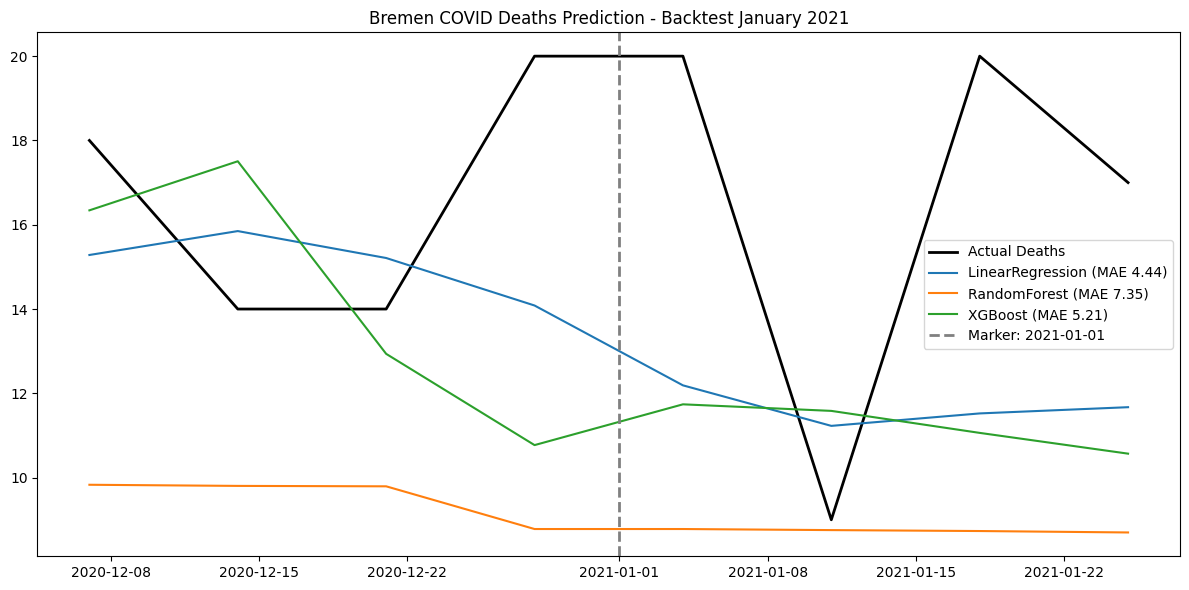

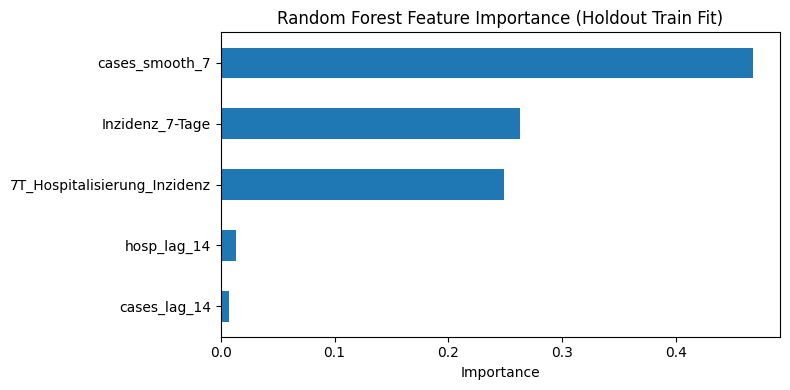

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

# --------------------------------------------------
# 0. CONFIG
# --------------------------------------------------
path = "data/rki_merged_all_ages.csv"
BUNDESLAND = "Bremen"                 # <- change to any Bundesland name exactly as in your data
START_DATE = "2020-01-01"
END_DATE   = "2021-01-31"

# Holdout split (optional, same as your earlier approach)
cutoff = "2020-12-01"

# TimeSeries CV config
N_SPLITS = 5                          # 5 folds is a good default for daily series
GAP = 0                               # set >0 if you want a "gap" between train/test in CV
                                     # (useful if you worry about very short-term leakage)

# --------------------------------------------------
# 1. LOAD & PREP DATA (RKI merged, Bundesland level)
# --------------------------------------------------
df = pd.read_csv(path)

# Parse date column (Meldedatum)
df["Meldedatum"] = pd.to_datetime(df["Meldedatum"])

# Filter to Bundesland and aggregate across Altersgruppe (daily totals)
df_bl = df[df["Bundesland"] == BUNDESLAND].copy()

daily = (
    df_bl.groupby("Meldedatum", as_index=False)
    .agg(
        {
            "Faelle_neu": "sum",
            "Todesfaelle": "sum",
            "7T_Hospitalisierung_Faelle": "sum",
            # For rate-like columns, mean after aggregation is reasonable:
            "Inzidenz_7-Tage": "mean",
            "7T_Hospitalisierung_Inzidenz": "mean",
        }
    )
    .set_index("Meldedatum")
    .sort_index()
)

# Restrict time range


daily = daily.loc[START_DATE:END_DATE].copy()





# --------------------------------------------------
# FIX WEEKLY COLUMNS → DAILY
# --------------------------------------------------
weekly_cols = [
    "Inzidenz_7-Tage",
    "7T_Hospitalisierung_Inzidenz",
]

daily[weekly_cols] = daily[weekly_cols].ffill()


# --------------------------------------------------
# 2. FEATURE ENGINEERING (LEAKAGE-SAFE)
# --------------------------------------------------
daily["cases_lag_14"]     = daily["Faelle_neu"].shift(14)
daily["cases_smooth_7"]   = daily["Faelle_neu"].rolling(7).mean()
# daily["deaths_smooth_7"]  = daily["Todesfaelle"].rolling(7).mean()
daily["hosp_lag_14"]       = daily["7T_Hospitalisierung_Faelle"].shift(14)

features = [
    "cases_lag_14",
    "cases_smooth_7",
    "Inzidenz_7-Tage",
    "7T_Hospitalisierung_Inzidenz",
    "hosp_lag_14",
]
target = "Todesfaelle"

df_model = daily[features + [target]].dropna().copy()

print(f"Bundesland: {BUNDESLAND}")
print(f"Modeling rows after dropna: {len(df_model)}")
print(f"Date range used: {df_model.index.min().date()} -> {df_model.index.max().date()}")

# --------------------------------------------------
# 3. HOLDOUT SPLIT (Optional)
# --------------------------------------------------
train_holdout = df_model[df_model.index < cutoff]
test_holdout  = df_model.loc[cutoff:END_DATE]

X_train_h, y_train_h = train_holdout[features], train_holdout[target]
X_test_h,  y_test_h  = test_holdout[features],  test_holdout[target]

print(f"\nHoldout split cutoff: {cutoff}")
print(f"Holdout Training Days: {len(X_train_h)}, Testing Days: {len(X_test_h)}")

# --------------------------------------------------
# 4. MODELS
# --------------------------------------------------
lr = LinearRegression()

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1,
)

xgb = XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.9,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

models = {
    "LinearRegression": lr,
    "RandomForest": rf,
    "XGBoost": xgb,
}

# --------------------------------------------------
# 5. TIME SERIES CROSS-VALIDATION (Rolling/Expanding)
# --------------------------------------------------
def time_series_cv_mae(df_model, features, target, model, n_splits=5, gap=0):
    """
    Returns:
      fold_maes: list of MAE for each fold
      oof_pred: out-of-fold prediction series aligned to df_model index (NaN where not predicted)
    """
    X = df_model[features].values
    y = df_model[target].values
    idx = df_model.index

    tscv = TimeSeriesSplit(n_splits=n_splits, gap=gap)
    fold_maes = []
    oof_pred = pd.Series(index=idx, dtype=float)

    for fold, (train_idx, val_idx) in enumerate(tscv.split(X), start=1):
        X_tr, y_tr = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]

        model_fold = model  # sklearn/xgb models can be refit each time
        model_fold.fit(X_tr, y_tr)
        pred_val = model_fold.predict(X_val)

        mae = mean_absolute_error(y_val, pred_val)
        fold_maes.append(mae)

        oof_pred.iloc[val_idx] = pred_val

        print(f"  Fold {fold}: train={len(train_idx)} val={len(val_idx)} MAE={mae:.3f}")

    return fold_maes, oof_pred

print("\n=== Time Series CV (MAE) ===")
cv_results = {}

for name, model in models.items():
    print(f"\n{name}")
    fold_maes, oof_pred = time_series_cv_mae(
        df_model=df_model,
        features=features,
        target=target,
        model=model,
        n_splits=N_SPLITS,
        gap=GAP,
    )
    cv_results[name] = {
        "fold_maes": fold_maes,
        "mean_mae": float(np.mean(fold_maes)),
        "std_mae": float(np.std(fold_maes)),
        "oof_pred": oof_pred,
    }

print("\n=== CV Summary ===")
for name, res in cv_results.items():
    print(f"{name:16s}  MAE: {res['mean_mae']:.3f} ± {res['std_mae']:.3f}")

# --------------------------------------------------
# 6. HOLDOUT EVALUATION (Same as your earlier comparison)
# --------------------------------------------------
print("\n=== Holdout Test (cutoff-based) ===")
holdout_preds = {}

for name, model in models.items():
    model.fit(X_train_h, y_train_h)
    pred = model.predict(X_test_h)
    mae = mean_absolute_error(y_test_h, pred)
    holdout_preds[name] = pred
    print(f"{name:16s}  Holdout MAE: {mae:.3f}")


# --------------------------------------------------
# 7. HOLDOUT PLOT WITH MAE IN LEGEND
# --------------------------------------------------
plt.figure(figsize=(12, 6))

# Actual
plt.plot(test_holdout.index, y_test_h, color="black", label="Actual Deaths", linewidth=2)

# Predictions + MAE in label
for name, pred in holdout_preds.items():
    mae = mean_absolute_error(y_test_h, pred)
    plt.plot(test_holdout.index, pred, label=f"{name} (MAE {mae:.2f})")

plt.title(f"{BUNDESLAND} COVID Deaths Prediction - Backtest January 2021")
plt.axvline(pd.to_datetime("2021-01-01"), color="gray", linestyle="--", linewidth=2, label="Marker: 2021-01-01")
plt.legend()
plt.tight_layout()
plt.show()



# --------------------------------------------------
# 8. FEATURE IMPORTANCE (RF) - fit on full training holdout set
# --------------------------------------------------
rf.fit(X_train_h, y_train_h)
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 4))
importances.plot(kind="barh")
plt.title("Random Forest Feature Importance (Holdout Train Fit)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## Forecast 2022

In [49]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt

# from sklearn.model_selection import TimeSeriesSplit
# from sklearn.metrics import mean_absolute_error
# from sklearn.linear_model import LinearRegression
# from sklearn.ensemble import RandomForestRegressor

# from xgboost import XGBRegressor

# # --------------------------------------------------
# # 0. CONFIG
# # --------------------------------------------------
# path = "data/rki_merged_all_ages.csv"
# BUNDESLAND = "Bremen"                 # <- change to any Bundesland name exactly as in your data
# START_DATE = "2020-10-01"
# END_DATE   = "2022-01-31"

# # Holdout split (optional, same as your earlier approach)
# cutoff = "2021-12-01"

# # TimeSeries CV config
# N_SPLITS = 5                          # 5 folds is a good default for daily series
# GAP = 0                               # set >0 if you want a "gap" between train/test in CV
#                                      # (useful if you worry about very short-term leakage)

# # --------------------------------------------------
# # 1. LOAD & PREP DATA (RKI merged, Bundesland level)
# # --------------------------------------------------
# df = pd.read_csv(path)

# # Parse date column (Meldedatum)
# df["Meldedatum"] = pd.to_datetime(df["Meldedatum"])

# # Filter to Bundesland and aggregate across Altersgruppe (daily totals)
# df_bl = df[df["Bundesland"] == BUNDESLAND].copy()

# daily = (
#     df_bl.groupby("Meldedatum", as_index=False)
#     .agg(
#         {
#             "Faelle_neu": "sum",
#             "Todesfaelle": "sum",
#             "7T_Hospitalisierung_Faelle": "sum",
#             # For rate-like columns, mean after aggregation is reasonable:
#             "Inzidenz_7-Tage": "mean",
#             "7T_Hospitalisierung_Inzidenz": "mean",
#         }
#     )
#     .set_index("Meldedatum")
#     .sort_index()
# )

# # Restrict time range
# daily = daily.loc[START_DATE:END_DATE].copy()

# # --------------------------------------------------
# # FIX WEEKLY COLUMNS → DAILY
# # --------------------------------------------------
# weekly_cols = [
#     "Inzidenz_7-Tage",
#     "7T_Hospitalisierung_Inzidenz",
# ]

# daily[weekly_cols] = daily[weekly_cols].ffill()


# # --------------------------------------------------
# # 2. FEATURE ENGINEERING (LEAKAGE-SAFE)
# # --------------------------------------------------
# daily["cases_lag_14"]     = daily["Faelle_neu"].shift(14)
# daily["cases_smooth_7"]   = daily["Faelle_neu"].rolling(7).mean()
# # daily["deaths_smooth_7"]  = daily["Todesfaelle"].rolling(7).mean()
# daily["hosp_lag_14"]       = daily["7T_Hospitalisierung_Faelle"].shift(14)

# features = [
#     "cases_lag_14",
#     "cases_smooth_7",
#     "Inzidenz_7-Tage",
#     "7T_Hospitalisierung_Inzidenz",
#     "hosp_lag_14",
# ]
# target = "Todesfaelle"

# df_model = daily[features + [target]].dropna().copy()

# print(f"Bundesland: {BUNDESLAND}")
# print(f"Modeling rows after dropna: {len(df_model)}")
# print(f"Date range used: {df_model.index.min().date()} -> {df_model.index.max().date()}")

# # --------------------------------------------------
# # 3. HOLDOUT SPLIT (Optional)
# # --------------------------------------------------
# train_holdout = df_model[df_model.index < cutoff]
# test_holdout  = df_model.loc[cutoff:END_DATE]

# X_train_h, y_train_h = train_holdout[features], train_holdout[target]
# X_test_h,  y_test_h  = test_holdout[features],  test_holdout[target]

# print(f"\nHoldout split cutoff: {cutoff}")
# print(f"Holdout Training Days: {len(X_train_h)}, Testing Days: {len(X_test_h)}")

# # --------------------------------------------------
# # 4. MODELS
# # --------------------------------------------------
# lr = LinearRegression()

# rf = RandomForestRegressor(
#     n_estimators=300,
#     max_depth=4,
#     min_samples_leaf=5,
#     min_samples_split=5,
#     random_state=42,
#     n_jobs=-1,
# )

# xgb = XGBRegressor(
#     n_estimators=800,
#     learning_rate=0.03,
#     max_depth=4,
#     subsample=0.8,
#     colsample_bytree=0.9,
#     reg_alpha=0.0,
#     reg_lambda=1.0,
#     objective="reg:squarederror",
#     random_state=42,
#     n_jobs=-1,
# )

# models = {
#     "LinearRegression": lr,
#     "RandomForest": rf,
#     "XGBoost": xgb,
# }

# # --------------------------------------------------
# # 5. TIME SERIES CROSS-VALIDATION (Rolling/Expanding)
# # --------------------------------------------------
# def time_series_cv_mae(df_model, features, target, model, n_splits=5, gap=0):
#     """
#     Returns:
#       fold_maes: list of MAE for each fold
#       oof_pred: out-of-fold prediction series aligned to df_model index (NaN where not predicted)
#     """
#     X = df_model[features].values
#     y = df_model[target].values
#     idx = df_model.index

#     tscv = TimeSeriesSplit(n_splits=n_splits, gap=gap)
#     fold_maes = []
#     oof_pred = pd.Series(index=idx, dtype=float)

#     for fold, (train_idx, val_idx) in enumerate(tscv.split(X), start=1):
#         X_tr, y_tr = X[train_idx], y[train_idx]
#         X_val, y_val = X[val_idx], y[val_idx]

#         model_fold = model  # sklearn/xgb models can be refit each time
#         model_fold.fit(X_tr, y_tr)
#         pred_val = model_fold.predict(X_val)

#         mae = mean_absolute_error(y_val, pred_val)
#         fold_maes.append(mae)

#         oof_pred.iloc[val_idx] = pred_val

#         print(f"  Fold {fold}: train={len(train_idx)} val={len(val_idx)} MAE={mae:.3f}")

#     return fold_maes, oof_pred

# print("\n=== Time Series CV (MAE) ===")
# cv_results = {}

# for name, model in models.items():
#     print(f"\n{name}")
#     fold_maes, oof_pred = time_series_cv_mae(
#         df_model=df_model,
#         features=features,
#         target=target,
#         model=model,
#         n_splits=N_SPLITS,
#         gap=GAP,
#     )
#     cv_results[name] = {
#         "fold_maes": fold_maes,
#         "mean_mae": float(np.mean(fold_maes)),
#         "std_mae": float(np.std(fold_maes)),
#         "oof_pred": oof_pred,
#     }

# print("\n=== CV Summary ===")
# for name, res in cv_results.items():
#     print(f"{name:16s}  MAE: {res['mean_mae']:.3f} ± {res['std_mae']:.3f}")

# # --------------------------------------------------
# # 6. HOLDOUT EVALUATION (Same as your earlier comparison)
# # --------------------------------------------------
# print("\n=== Holdout Test (cutoff-based) ===")
# holdout_preds = {}

# for name, model in models.items():
#     model.fit(X_train_h, y_train_h)
#     pred = model.predict(X_test_h)
#     mae = mean_absolute_error(y_test_h, pred)
#     holdout_preds[name] = pred
#     print(f"{name:16s}  Holdout MAE: {mae:.3f}")


# # --------------------------------------------------
# # 7. HOLDOUT PLOT WITH MAE IN LEGEND
# # --------------------------------------------------
# plt.figure(figsize=(12, 6))

# # Actual
# plt.plot(test_holdout.index, y_test_h, color="black", label="Actual Deaths", linewidth=2)

# # Predictions + MAE in label
# for name, pred in holdout_preds.items():
#     mae = mean_absolute_error(y_test_h, pred)
#     plt.plot(test_holdout.index, pred, label=f"{name} (MAE {mae:.2f})")

# plt.title(f"{BUNDESLAND} COVID Deaths Prediction (Holdout Test)")
# plt.axvline(pd.to_datetime("2022-01-01"), color="gray", linestyle="--", linewidth=2, label="Marker: 2022-01-01")
# plt.legend()
# plt.tight_layout()
# plt.show()



# # --------------------------------------------------
# # 8. FEATURE IMPORTANCE (RF) - fit on full training holdout set
# # --------------------------------------------------
# rf.fit(X_train_h, y_train_h)
# importances = pd.Series(rf.feature_importances_, index=features).sort_values()

# plt.figure(figsize=(8, 4))
# importances.plot(kind="barh")
# plt.title("Random Forest Feature Importance (Holdout Train Fit)")
# plt.xlabel("Importance")
# plt.tight_layout()
# plt.show()


Rows in Jan 2022 (daily): 31

Bundesland: Bremen
Modeling rows after dropna: 474
Date range used: 2020-10-15 -> 2022-01-31

Holdout split cutoff: 2021-12-01
Holdout Training Days: 412, Testing Days: 62

=== Time Series CV (MAE) ===

LinearRegression
  Fold 1: train=79 val=79 MAE=0.844
  Fold 2: train=158 val=79 MAE=1.661
  Fold 3: train=237 val=79 MAE=0.525
  Fold 4: train=316 val=79 MAE=0.658
  Fold 5: train=395 val=79 MAE=2.654

RandomForest
  Fold 1: train=79 val=79 MAE=0.821
  Fold 2: train=158 val=79 MAE=1.237
  Fold 3: train=237 val=79 MAE=0.412
  Fold 4: train=316 val=79 MAE=0.729
  Fold 5: train=395 val=79 MAE=0.370

XGBoost
  Fold 1: train=79 val=79 MAE=0.571
  Fold 2: train=158 val=79 MAE=0.854
  Fold 3: train=237 val=79 MAE=0.244
  Fold 4: train=316 val=79 MAE=1.256
  Fold 5: train=395 val=79 MAE=0.417

=== CV Summary ===
LinearRegression  MAE: 1.268 ± 0.797
RandomForest      MAE: 0.714 ± 0.315
XGBoost           MAE: 0.668 ± 0.356

=== Holdout Test (cutoff-based) ===
LinearR

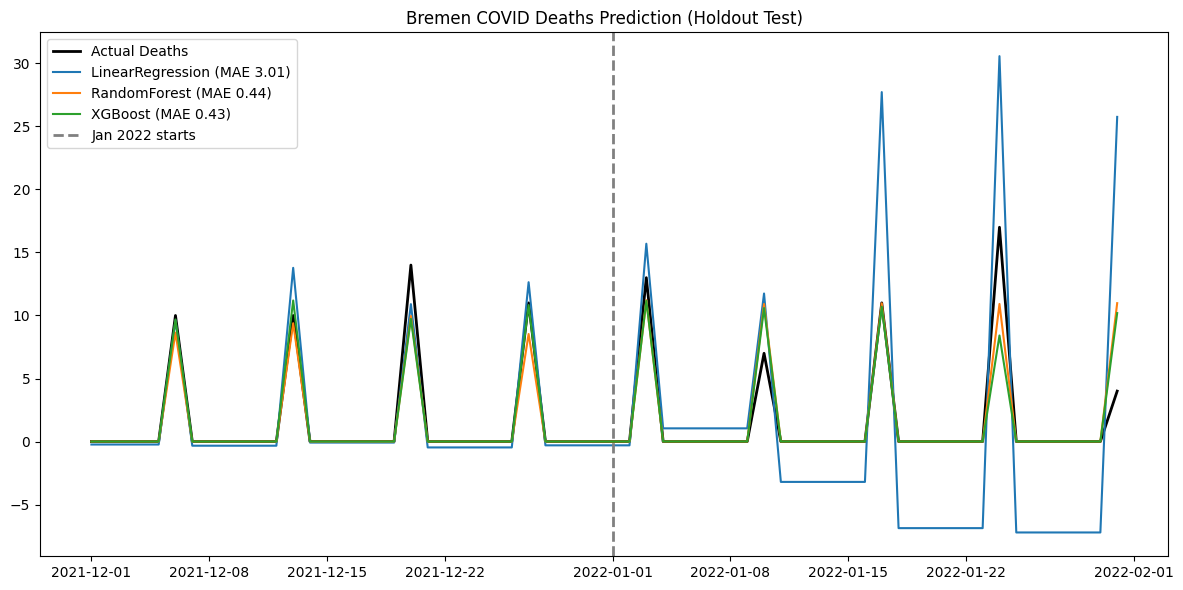

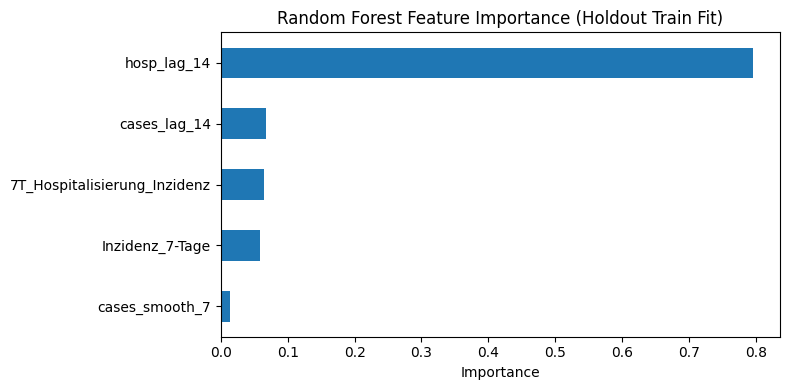


Rows in exported Jan 2022 predictions: 31
        Date  Region  Predicted_Deaths
0 2022-01-01  Bremen              0.00
1 2022-01-02  Bremen              0.00
2 2022-01-03  Bremen             12.65
3 2022-01-04  Bremen              0.01
4 2022-01-05  Bremen              0.01

✅ January 2022 predictions exported to: Bremen_January_2022_Predicted_Deaths.csv


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

# --------------------------------------------------
# 0. CONFIG
# --------------------------------------------------
path = "data/rki_merged_all_ages.csv"
BUNDESLAND = "Bremen"                 # <- change to any Bundesland name exactly as in your data
START_DATE = "2020-10-01"
END_DATE   = "2022-01-31"

# Holdout split (optional, same as your earlier approach)
cutoff = "2021-12-01"

# TimeSeries CV config
N_SPLITS = 5
GAP = 0

# --------------------------------------------------
# 1. LOAD & PREP DATA (RKI merged, Bundesland level)
# --------------------------------------------------
df = pd.read_csv(path)

# Parse date column (Meldedatum)
df["Meldedatum"] = pd.to_datetime(df["Meldedatum"])

# Choose Bundesland
df_bl = df[df["Bundesland"] == BUNDESLAND].copy()

# Aggregate across Altersgruppe (daily totals)
daily = (
    df_bl.groupby("Meldedatum", as_index=False)
    .agg(
        {
            "Faelle_neu": "sum",
            "Todesfaelle": "sum",
            "7T_Hospitalisierung_Faelle": "sum",
            # rate-like columns:
            "Inzidenz_7-Tage": "mean",
            "7T_Hospitalisierung_Inzidenz": "mean",
        }
    )
    .set_index("Meldedatum")
    .sort_index()
)

# Restrict time range
daily = daily.loc[START_DATE:END_DATE].copy()

# --------------------------------------------------
# 1B. FIX: FORCE FULL DAILY INDEX (so Jan has 31 rows)
# --------------------------------------------------
full_idx = pd.date_range(START_DATE, END_DATE, freq="D")
daily = daily.reindex(full_idx)
daily.index.name = "Meldedatum"

# Count-like cols: assume missing day => 0 (or missing report; this is the common modeling choice)
count_cols = ["Faelle_neu", "Todesfaelle", "7T_Hospitalisierung_Faelle"]
daily[count_cols] = daily[count_cols].fillna(0)

# Rate-like cols: carry forward last known value
rate_cols = ["Inzidenz_7-Tage", "7T_Hospitalisierung_Inzidenz"]
daily[rate_cols] = daily[rate_cols].ffill().bfill()

# ---------------------------
daily["Faelle_neu"] = daily["Faelle_neu"].ffill().fillna(0)
daily["7T_Hospitalisierung_Faelle"] = daily["7T_Hospitalisierung_Faelle"].ffill().fillna(0)

# target stays NaN where unknown


print("Rows in Jan 2022 (daily):", len(daily.loc["2022-01-01":"2022-01-31"]))

# --------------------------------------------------
# 2. FEATURE ENGINEERING (LEAKAGE-SAFE)
# --------------------------------------------------
daily["cases_lag_14"]    = daily["Faelle_neu"].shift(14)
daily["cases_smooth_7"]  = daily["Faelle_neu"].rolling(7).mean()
daily["hosp_lag_14"]     = daily["7T_Hospitalisierung_Faelle"].shift(14)

features = [
    "cases_lag_14",
    "cases_smooth_7",
    "Inzidenz_7-Tage",
    "7T_Hospitalisierung_Inzidenz",
    "hosp_lag_14",
]
target = "Todesfaelle"

df_model = daily[features + [target]].dropna().copy()

print(f"\nBundesland: {BUNDESLAND}")
print(f"Modeling rows after dropna: {len(df_model)}")
print(f"Date range used: {df_model.index.min().date()} -> {df_model.index.max().date()}")

# --------------------------------------------------
# 3. HOLDOUT SPLIT
# --------------------------------------------------
train_holdout = df_model[df_model.index < cutoff]
test_holdout  = df_model.loc[cutoff:END_DATE]

X_train_h, y_train_h = train_holdout[features], train_holdout[target]
X_test_h,  y_test_h  = test_holdout[features],  test_holdout[target]

print(f"\nHoldout split cutoff: {cutoff}")
print(f"Holdout Training Days: {len(X_train_h)}, Testing Days: {len(X_test_h)}")

# --------------------------------------------------
# 4. MODELS
# --------------------------------------------------
lr = LinearRegression()

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1,
)

xgb = XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.9,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

models = {
    "LinearRegression": lr,
    "RandomForest": rf,
    "XGBoost": xgb,
}

# --------------------------------------------------
# 5. TIME SERIES CROSS-VALIDATION
# --------------------------------------------------
def time_series_cv_mae(df_model, features, target, model, n_splits=5, gap=0):
    X = df_model[features].values
    y = df_model[target].values

    tscv = TimeSeriesSplit(n_splits=n_splits, gap=gap)
    fold_maes = []

    for fold, (train_idx, val_idx) in enumerate(tscv.split(X), start=1):
        X_tr, y_tr = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]

        model.fit(X_tr, y_tr)
        pred_val = model.predict(X_val)

        mae = mean_absolute_error(y_val, pred_val)
        fold_maes.append(mae)

        print(f"  Fold {fold}: train={len(train_idx)} val={len(val_idx)} MAE={mae:.3f}")

    return fold_maes

print("\n=== Time Series CV (MAE) ===")
cv_results = {}

for name, model in models.items():
    print(f"\n{name}")
    fold_maes = time_series_cv_mae(
        df_model=df_model,
        features=features,
        target=target,
        model=model,
        n_splits=N_SPLITS,
        gap=GAP,
    )
    cv_results[name] = {
        "fold_maes": fold_maes,
        "mean_mae": float(np.mean(fold_maes)),
        "std_mae": float(np.std(fold_maes)),
    }

print("\n=== CV Summary ===")
for name, res in cv_results.items():
    print(f"{name:16s}  MAE: {res['mean_mae']:.3f} ± {res['std_mae']:.3f}")

# --------------------------------------------------
# 6. HOLDOUT EVALUATION
# --------------------------------------------------
print("\n=== Holdout Test (cutoff-based) ===")
holdout_preds = {}

for name, model in models.items():
    model.fit(X_train_h, y_train_h)
    pred = model.predict(X_test_h)
    mae = mean_absolute_error(y_test_h, pred)
    holdout_preds[name] = pred
    print(f"{name:16s}  Holdout MAE: {mae:.3f}")

# --------------------------------------------------
# 7. HOLDOUT PLOT WITH MAE IN LEGEND
# --------------------------------------------------
plt.figure(figsize=(12, 6))
plt.plot(test_holdout.index, y_test_h, color="black", label="Actual Deaths", linewidth=2)

for name, pred in holdout_preds.items():
    mae = mean_absolute_error(y_test_h, pred)
    plt.plot(test_holdout.index, pred, label=f"{name} (MAE {mae:.2f})")

plt.title(f"{BUNDESLAND} COVID Deaths Prediction (Holdout Test)")
plt.axvline(pd.to_datetime("2022-01-01"), color="gray", linestyle="--", linewidth=2, label="Jan 2022 starts")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. FEATURE IMPORTANCE (RF)
# --------------------------------------------------
rf.fit(X_train_h, y_train_h)
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 4))
importances.plot(kind="barh")
plt.title("Random Forest Feature Importance (Holdout Train Fit)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. FINAL JAN 2022 PREDICTIONS + CSV EXPORT (one row per day)
# --------------------------------------------------
final_train = df_model[df_model.index < "2022-01-01"]
jan_2022    = df_model.loc["2022-01-01":"2022-01-31"]

X_final_train = final_train[features]
y_final_train = final_train[target]
X_jan_2022 = jan_2022[features]

final_model = xgb  # choose best model (change to rf or lr if needed)
final_model.fit(X_final_train, y_final_train)

jan_2022_preds = final_model.predict(X_jan_2022)

output_df = pd.DataFrame({
    "Date": jan_2022.index,
    "Region": BUNDESLAND,
    "Predicted_Deaths": np.round(jan_2022_preds, 2),
})

print("\nRows in exported Jan 2022 predictions:", len(output_df))
print(output_df.head())

output_path = f"{BUNDESLAND}_January_2022_Predicted_Deaths.csv"
output_df.to_csv(output_path, index=False)
print(f"\n✅ January 2022 predictions exported to: {output_path}")
